# Fractional-DD Collapse / Ephemeris-Predicted Phase Graph Classifier
## Authentic, Full-Spoof, and Mixed-Tracking Experiments

This notebook implements one simple physical rule for all three scenarios:

$$\boxed{\text{fractional DD collapses}\;\land\;\text{claimed geometry predicts separable phase}\;\Longrightarrow\;\text{pairwise common-source evidence}}$$

Each tracked PRN becomes a graph node. Both pairwise conditions are evaluated in the observable fractional-carrier domain: measured fractional-DD collapse and ephemeris-predicted phase separation after projection through the same antenna baseline. Ephemeris AoA remains available in degrees for interpretation, but degrees do not define the primary edge. The graph distinguishes:

- **No detected group evidence:** no corroborated common-signature component;
- **Pair alert:** exactly two PRNs provide sensor-distinguishable fractional-DD collapse evidence;
- **Corroborated component:** at least three PRNs have complete, internally collapsed pair evidence.

The same thresholds and label-free algorithm are used for all recordings. Ground-truth labels appear only in the final post-hoc evaluation.

## 1. Pairwise reasoning before graph construction

For PRNs $i$ and $j$, the method asks two separate questions:

1. Is the direct wrapped pairwise DD close to zero in carrier cycles?
2. Should those claimed directions have produced distinguishable fractional phase on this antenna baseline?

The four logical outcomes are:

| Fractional-DD relation | Ephemeris-predicted phase relation | Graph interpretation |
|---|---|---|
| Collapsed | Distinguishable | Red pairwise common-source candidate edge |
| Collapsed | Aliased / weakly separated | Orange predicted-phase-aliased collapse edge |
| Not collapsed | Distinguishable | No common-source edge; may be authentic–authentic or authentic–spoof |
| Not collapsed | Aliased / weakly separated | No common-source edge; geometry is non-informative for this pair |

Thus, `fractional DD not collapsed` means only

$$\text{no common-source edge between }i\text{ and }j,$$

not that both satellites are automatically authentic. Classification comes from the complete graph structure.

In [1]:
from itertools import combinations
from pathlib import Path
import importlib

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns

import aoa_pipeline
import graph_component_classifier
importlib.reload(aoa_pipeline)
importlib.reload(graph_component_classifier)

from aoa_pipeline import (
    DatasetConfig,
    compute_ephemeris_predicted_pair_separation_cycles,
    run_dataset,
    wrap_cycles,
)
from graph_component_classifier import (
    ComponentClassifierConfig,
    EvidenceState,
    classify_common_source_components,
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 150)
sns.set_theme(style="whitegrid", context="notebook")

## 2. One fixed configuration for three scenarios

The baseline ratio is

$$\rho=\frac{D}{\lambda}=1,$$

where $D$ is the antenna separation and $\lambda$ is the GPS L1 wavelength.

A pair is fractional-DD collapsed when its temporally aggregated wrapped measured separation is no greater than $\tau_c$. A collapsed pair is sensor-distinguishable when the ephemeris-predicted wrapped pair separation is at least $\tau_p$. This run uses

$$\tau_c=0.03\;\text{cycles},\qquad\tau_p=0.05\;\text{cycles}.$$

The two thresholds have the same unit but different roles and are calibrated separately: $\tau_c$ limits measured collapse, whereas $\tau_p$ requires a minimum predicted sensor separation. Both are fixed across all three experiments.

In [2]:
OUTPUT_DIR = Path("outputs/aoa_paper/three_scenario_graph_classifier")
SAVE_OUTPUTS = False

BASELINE_OVER_WAVELENGTH = 1.0
FRACTIONAL_DD_COLLAPSE_THRESHOLD_CYCLES = 0.03
EPHEMERIS_PREDICTED_SEPARATION_THRESHOLD_CYCLES = 0.05
MIN_TARGET_EPOCHS = 20
MIN_PAIR_EPOCHS = 10
COMPONENT_CLASSIFIER_CONFIG = ComponentClassifierConfig(
    fractional_dd_collapse_threshold_cycles=FRACTIONAL_DD_COLLAPSE_THRESHOLD_CYCLES,
    ephemeris_predicted_separation_threshold_cycles=EPHEMERIS_PREDICTED_SEPARATION_THRESHOLD_CYCLES,
    min_pair_epochs=MIN_PAIR_EPOCHS,
    min_observed_pair_coverage=1.0,
    min_collapse_fraction=1.0,
)

SCENARIO_SPECS = {
    "Authentic": {
        "receiver1": Path("dataset/Authentic/raw_data_1.ubx"),
        "receiver2": Path("dataset/Authentic/raw_data_2.ubx"),
        "start_index": 0,
        "length": 120,
    },
    "Full spoof": {
        "receiver1": Path("dataset/SP-2025-04-24/raw_data_1.ubx"),
        "receiver2": Path("dataset/SP-2025-04-24/raw_data_2.ubx"),
        "start_index": 0,
        "length": 120,
    },
    "Mixed tracking": {
        "receiver1": Path("dataset/sp-partial-19-06/18-06/COM3___9600_260618_095042.ubx"),
        "receiver2": Path("dataset/sp-partial-19-06/18-06/COM4___9600_260618_095054.ubx"),
        "start_index": 0,
        "length": 34,
    },
}

display(pd.DataFrame([
    {
        "scenario": name,
        "receiver1": str(spec["receiver1"]),
        "receiver2": str(spec["receiver2"]),
        "start_index": spec["start_index"],
        "analysis_epochs": spec["length"],
        "baseline_over_wavelength": BASELINE_OVER_WAVELENGTH,
        "collapse_threshold_cycles": FRACTIONAL_DD_COLLAPSE_THRESHOLD_CYCLES,
        "predicted_separation_threshold_cycles": EPHEMERIS_PREDICTED_SEPARATION_THRESHOLD_CYCLES,
    }
    for name, spec in SCENARIO_SPECS.items()
]))

,scenario,receiver1,receiver2,start_index,analysis_epochs,baseline_over_wavelength,collapse_threshold_cycles,predicted_separation_threshold_cycles
0,Authentic,dataset/Authentic/raw_data_1.ubx,dataset/Authentic/raw_data_2.ubx,0,120,1.0,0.03,0.05
1,Full spoof,dataset/SP-2025-04-24/raw_data_1.ubx,dataset/SP-2025-04-24/raw_data_2.ubx,0,120,1.0,0.03,0.05
2,Mixed tracking,dataset/sp-partial-19-06/18-06/COM3___9600_260...,dataset/sp-partial-19-06/18-06/COM4___9600_260...,0,34,1.0,0.03,0.05


## 3. Pairwise fractional-DD collapse

For PRN pair $(i,j)$, the direct carrier-phase double difference is

$$d_{ij,k}^{DD}=(\phi_{2,i,k}-\phi_{1,i,k})-(\phi_{2,j,k}-\phi_{1,j,k}).$$

where $k$ denotes a synchronized epoch.

No fixed reference satellite is selected. The fractional DD is

$$f_{ij,k}=\operatorname{wrap}(d_{ij,k}^{DD}).$$

## 4. Fractional-DD collapse and ephemeris-predicted phase separation

Carrier ambiguity is removed using the cycle-wrapping operator

$$\operatorname{wrap}(x)=\left((x+\tfrac12)\bmod1\right)-\tfrac12.$$

### Fractional-DD collapse in cycles

The epoch-level collapse magnitude is

$$c_{ij,k}^{DD}=|f_{ij,k}|,$$

Its robust temporal summary is

$$C_{ij}^{DD}=\operatorname{median}_{k}\,c_{ij,k}^{DD}\quad[\text{cycles}].$$

Thus, `fractional DD collapsed` means $C_{ij}^{DD}\le\tau_c$.

### Ephemeris geometry projected into carrier cycles

Ephemeris does not contain a measured DD. It supplies the claimed line-of-sight geometry. For a horizontal baseline at azimuth $\beta$, the baseline projection and human-readable AoA are

$$\mu_{i,k}^{eph}=\cos E_{i,k}\cos(A_{i,k}-\beta)=\cos\alpha_{i,k}^{eph},\qquad \alpha_{i,k}^{eph}=\arccos(\mu_{i,k}^{eph})\quad[^\circ].$$

The predicted inter-antenna phase for satellite $i$ is $q_{i,k}^{eph}=\rho\mu_{i,k}^{eph}$ cycles. Therefore, on the same jointly valid epochs used for the measured pair,

$$q_{ij,k}^{eph}=\rho\left(\mu_{i,k}^{eph}-\mu_{j,k}^{eph}\right)\quad[\text{cycles}],$$

$$p_{ij,k}^{eph}=\left|\operatorname{wrap}\left(q_{ij,k}^{eph}\right)\right|,\qquad P_{ij}^{eph}=\operatorname{median}_{k}p_{ij,k}^{eph}\quad[\text{cycles}].$$

`Predicted phase distinguishable` means $P_{ij}^{eph}\ge\tau_p$. Wrapping is essential because the measured fractional DD cannot distinguish phase separations that differ by an integer number of cycles.

## 5. Two edge types and one no-edge relation

The measured-collapse and predicted-separation indicators are

$$B_{ij}=\mathbf 1\!\left[C_{ij}^{DD}\le\tau_c\right],\qquad G_{ij}=\mathbf 1\!\left[P_{ij}^{eph}\ge\tau_p\right].$$

The red pairwise common-source candidate adjacency is

$$H_{ij}=B_{ij}G_{ij}.$$

The categorical relation matrix used in the heatmaps is

$$M_{ij}=\begin{cases}
2,&B_{ij}=1\ \text{and}\ G_{ij}=1\quad\text{(informative common-source candidate)},\\
1,&B_{ij}=1\ \text{and}\ G_{ij}=0\quad\text{(predicted-phase-aliased collapse)},\\
0,&B_{ij}=0\quad\text{(fractional DD not collapsed; no common-source edge)}.
\end{cases}$$

Red graph edges represent $M_{ij}=2$, orange dashed edges represent $M_{ij}=1$, and absent edges represent $M_{ij}=0$.

## 6. From pair edges to a validated common-signature group

### What the validation rule does

First, red informative edges nominate candidate groups:

$$G_h=(\mathcal V,\mathcal E_h),\qquad\mathcal E_h=\{(i,j):H_{ij}=1\}.$$

Here $\mathcal V$ is the eligible PRN set. The connected components of $G_h$ are candidates, not final decisions. Only red relations (`fractional DD collapsed AND predicted phase distinguishable`) can nominate a node. An orange relation cannot add a node by itself, although it may occur between two nodes already linked to the candidate by red evidence.

Next, every internal pair of a candidate $S$ is checked. Define

$$P(S)=\frac{|S|(|S|-1)}{2}.$$

Let $O_{ij}=1$ when pair $(i,j)$ has at least $n_{\min}=10$ jointly valid epochs. The two validation quantities are

$$q_o(S)=\frac{\sum_{i<j;\,i,j\in S}O_{ij}}{P(S)}\qquad\text{(observed-pair coverage)},$$

$$q_c(S)=\frac{\sum_{i<j;\,i,j\in S}B_{ij}}{\sum_{i<j;\,i,j\in S}O_{ij}}\qquad\text{(collapse fraction among observed pairs)}.$$

A candidate is accepted exactly when

$$|S|\ge 3,\qquad q_o(S)\ge 1.0,\qquad q_c(S)\ge 1.0.$$

Thus every possible internal pair must be observed and every observed internal pair must collapse. Red and orange pairs both satisfy the internal collapse requirement. One missing pair blocks corroboration because its relation is unknown; one observed non-collapse rejects the candidate because it contradicts a single coherent fractional signature. A two-node red component is retained as a pair alert rather than promoted to a group.


### Why a second validation step is needed

Connected components can join a chain such as $i\! -\! j\! -\! k$ even when the untested or contradictory pair $(i,k)$ does not support one coherent group. The complete internal check prevents that graph-transitivity shortcut. It verifies both that no pair was skipped and that every pair lies within the same collapse tolerance.

A two-node red component is retained only as a pair alert. It is compatible with two counterfeit PRNs, but one pair is not enough for this classifier to assign both endpoints to a corroborated group.

In [3]:
def build_fractional_dd_ephemeris_pair_evidence(
    single_difference_cycles, ephemeris_aoa_deg, nodes, baseline_over_wavelength
):
    """Build both pair metrics from exactly the same jointly valid epochs."""
    single_difference = single_difference_cycles.reindex(columns=nodes)
    ephemeris_aoa = ephemeris_aoa_deg.reindex(
        index=single_difference.index, columns=nodes
    )
    epoch_rows = []
    aggregate_rows = []
    for left_svid, right_svid in combinations(nodes, 2):
        joint = pd.DataFrame({
            "left_single_difference_cycles": single_difference[left_svid],
            "right_single_difference_cycles": single_difference[right_svid],
            "left_ephemeris_aoa_deg": ephemeris_aoa[left_svid],
            "right_ephemeris_aoa_deg": ephemeris_aoa[right_svid],
        }).dropna()
        if joint.empty:
            continue
        joint["fractional_dd_cycles"] = wrap_cycles(
            joint.left_single_difference_cycles
            - joint.right_single_difference_cycles
        )
        joint["fractional_dd_collapse_cycles"] = joint.fractional_dd_cycles.abs()
        joint["ephemeris_aoa_separation_deg"] = (
            joint.left_ephemeris_aoa_deg - joint.right_ephemeris_aoa_deg
        ).abs()
        joint["left_ephemeris_direction_cosine"] = np.cos(
            np.deg2rad(joint.left_ephemeris_aoa_deg)
        )
        joint["right_ephemeris_direction_cosine"] = np.cos(
            np.deg2rad(joint.right_ephemeris_aoa_deg)
        )
        joint["ephemeris_predicted_pair_cycles"] = baseline_over_wavelength * (
            joint.left_ephemeris_direction_cosine
            - joint.right_ephemeris_direction_cosine
        )
        joint["ephemeris_predicted_pair_cycles_wrapped"] = wrap_cycles(
            joint.ephemeris_predicted_pair_cycles
        )
        joint["ephemeris_predicted_pair_separation_cycles"] = (
            compute_ephemeris_predicted_pair_separation_cycles(
                joint.left_ephemeris_aoa_deg,
                joint.right_ephemeris_aoa_deg,
                baseline_over_wavelength=baseline_over_wavelength,
            )
        )
        joint = joint.reset_index().rename(
            columns={joint.index.name or "index": "epoch_index"}
        )
        joint.insert(1, "left_svid", int(left_svid))
        joint.insert(2, "right_svid", int(right_svid))
        epoch_rows.append(joint)
        aggregate_rows.append({
            "pair": f"PRN {left_svid}–PRN {right_svid}",
            "left_svid": int(left_svid),
            "right_svid": int(right_svid),
            "median_fractional_dd_collapse_cycles": float(
                joint.fractional_dd_collapse_cycles.median()
            ),
            "median_ephemeris_predicted_pair_separation_cycles": float(
                joint.ephemeris_predicted_pair_separation_cycles.median()
            ),
            "median_ephemeris_aoa_separation_deg": float(
                joint.ephemeris_aoa_separation_deg.median()
            ),
            "epoch_count": len(joint),
        })
    epoch_columns = [
        "epoch_index", "left_svid", "right_svid",
        "left_single_difference_cycles", "right_single_difference_cycles",
        "left_ephemeris_aoa_deg", "right_ephemeris_aoa_deg",
        "fractional_dd_cycles", "fractional_dd_collapse_cycles",
        "ephemeris_aoa_separation_deg",
        "left_ephemeris_direction_cosine", "right_ephemeris_direction_cosine",
        "ephemeris_predicted_pair_cycles",
        "ephemeris_predicted_pair_cycles_wrapped",
        "ephemeris_predicted_pair_separation_cycles",
    ]
    aggregate_columns = [
        "pair", "left_svid", "right_svid",
        "median_fractional_dd_collapse_cycles",
        "median_ephemeris_predicted_pair_separation_cycles",
        "median_ephemeris_aoa_separation_deg", "epoch_count",
    ]
    epoch_pairs = (
        pd.concat(epoch_rows, ignore_index=True)
        if epoch_rows else pd.DataFrame(columns=epoch_columns)
    )
    aggregated_pairs = pd.DataFrame(aggregate_rows, columns=aggregate_columns)
    return epoch_pairs, aggregated_pairs

def symmetric_pair_matrix(nodes, pairs, value_column, diagonal=np.nan):
    matrix = pd.DataFrame(np.nan, index=nodes, columns=nodes, dtype=float)
    for row in pairs.itertuples():
        left, right = int(row.left_svid), int(row.right_svid)
        value = float(getattr(row, value_column))
        matrix.loc[left, right] = matrix.loc[right, left] = value
    for node in nodes:
        matrix.loc[node, node] = diagonal
    matrix.index.name = "PRN i"
    matrix.columns.name = "PRN j"
    return matrix

In [4]:
def analyze_scenario(name, spec):
    config = DatasetConfig(
        name=f"three_scenario_graph_classifier/{name.lower().replace(' ', '_')}",
        receiver1_path=spec["receiver1"],
        receiver2_path=spec["receiver2"],
        start_index=spec["start_index"],
        length=spec["length"],
        alpha_r_deg=None,
        reference_svid=None,
        selected_svids=None,
        excluded_reference_svids=None,
        reference_required_svids=None,
        excluded_analysis_svids=None,
        sync_tow_decimals=0,
        use_navpvt_time_correction=True,
        single_difference_order="rx2-rx1",
        navsat_azimuth_bias_deg=0.0,
        baseline_over_wavelength=BASELINE_OVER_WAVELENGTH,
    )
    run = run_dataset(config)
    common_svids = sorted(set(run.single_difference_cycles.columns) & set(run.ephemeris_aoa_deg.columns))
    nodes = [
        int(svid) for svid in common_svids
        if run.single_difference_cycles[svid].notna().sum() >= MIN_TARGET_EPOCHS
        and run.ephemeris_aoa_deg[svid].notna().sum() >= MIN_TARGET_EPOCHS
    ]
    epoch_pairs, aggregated_pairs = build_fractional_dd_ephemeris_pair_evidence(
        run.single_difference_cycles, run.ephemeris_aoa_deg, nodes,
        BASELINE_OVER_WAVELENGTH,
    )
    graph_result = classify_common_source_components(
        nodes, aggregated_pairs, config=COMPONENT_CLASSIFIER_CONFIG
    )
    pairs = graph_result.pair_evidence.merge(
        aggregated_pairs[[
            "left_svid", "right_svid", "median_ephemeris_aoa_separation_deg",
        ]],
        on=["left_svid", "right_svid"],
        how="left",
        validate="one_to_one",
    )
    pairs["relation_code"] = np.select(
        [
            pairs.informative_common_source_edge,
            pairs.fractional_dd_collapsed,
            pairs.observed,
        ],
        [2, 1, 0],
        default=np.nan,
    )
    pairs["specific_node_relation"] = pairs.relation.map({
        "informative_common_source": "fractional DD collapsed + predicted phase distinguishable → red candidate edge",
        "predicted_phase_aliased_collapse": "fractional DD collapsed + predicted phase aliased/weak → orange edge",
        "noncollapse": "fractional DD not collapsed → no common-source edge",
        "missing": "insufficient joint observations → undetermined relation",
    })

    components = tuple(graph_result.component_summary.component_svids)
    component_summary = graph_result.component_summary
    validated_components = list(graph_result.corroborated_groups)
    selected_group = tuple(sorted({node for group in validated_components for node in group}))

    scenario_decision = {
        EvidenceState.UNDETERMINED: "Undetermined: insufficient pair coverage",
        EvidenceState.NO_GROUP_EVIDENCE: "No threshold-qualified common-signature group detected",
        EvidenceState.PAIR_ALERTS_ONLY: "Pair-level common-spatial-signature alert(s); not a corroborated group",
        EvidenceState.SINGLE_ALL_NODE_COMPONENT: "All analyzable PRNs form one corroborated common-signature component",
        EvidenceState.SINGLE_SUBSET_COMPONENT: "One strict PRN subset forms a corroborated common-signature component",
        EvidenceState.MULTIPLE_COMPONENTS: "Multiple distinct common-signature components detected",
    }[graph_result.evidence_state]

    node_rows = []
    for node in nodes:
        incident = pairs.loc[pairs.left_svid.eq(node) | pairs.right_svid.eq(node)]
        node_rows.append({
            "svid": node,
            "fractional_dd_collapse_degree": int(incident.fractional_dd_collapsed.sum()),
            "informative_common_source_degree": int(incident.informative_common_source_edge.sum()),
            "predicted_phase_aliased_collapse_degree": int((
                incident.fractional_dd_collapsed & ~incident.predicted_phase_distinguishable
            ).sum()),
            "selected_common_source_member": node in selected_group,
            "graph_evidence_status": graph_result.node_summary.set_index("svid").loc[node, "status"],
        })
    node_summary = pd.DataFrame(node_rows)

    availability_nodes = sorted(set(run.single_difference_cycles.columns) | set(run.ephemeris_aoa_deg.columns))
    availability = pd.DataFrame({
        "svid": availability_nodes,
        "single_difference_epochs": [
            int(run.single_difference_cycles.get(node, pd.Series(dtype=float)).notna().sum()) for node in availability_nodes
        ],
        "ephemeris_epochs": [
            int(run.ephemeris_aoa_deg.get(node, pd.Series(dtype=float)).notna().sum()) for node in availability_nodes
        ],
    })
    availability["eligible"] = availability.svid.isin(nodes)

    return {
        "name": name, "run": run, "epoch_pairs": epoch_pairs, "pairs": pairs,
        "nodes": nodes, "components": components, "component_summary": component_summary,
        "validated_components": validated_components, "selected_group": selected_group,
        "pair_alerts": graph_result.pair_alerts, "evidence_state": graph_result.evidence_state,
        "scenario_decision": scenario_decision, "node_summary": node_summary,
        "availability": availability,
    }

## 7. Run the identical graph algorithm on all datasets

The method function above receives only observations and fixed settings. It does not receive the expected scenario or counterfeit PRN identities. For every scenario, it returns

$$\left(G_h,\;\{S_1,\ldots,S_L\},\;\widehat S,\;\widehat{\mathcal H}\right),$$

where $S_1,\ldots,S_L$ are red-edge candidate components, $\widehat S$ is the union of accepted component members, and $\widehat{\mathcal H}$ is the graph-topology decision. The components remain separate when interpreting the number of physical sources; their union is used only to list all PRNs with corroborated common-signature evidence.

In [5]:
results = {}
for scenario_name, scenario_spec in SCENARIO_SPECS.items():
    print(f"Running {scenario_name}...")
    results[scenario_name] = analyze_scenario(scenario_name, scenario_spec)
print("All scenarios completed.")

comparison_rows = []
for name, result in results.items():
    pairs = result["pairs"]
    comparison_rows.append({
        "scenario": name,
        "epochs": len(result["run"].epochs),
        "eligible_svids": tuple(result["nodes"]),
        "eligible_satellite_count": len(result["nodes"]),
        "pair_count": len(pairs),
        "baseline_over_wavelength": BASELINE_OVER_WAVELENGTH,
        "fractional_dd_threshold_cycles": FRACTIONAL_DD_COLLAPSE_THRESHOLD_CYCLES,
        "ephemeris_predicted_separation_threshold_cycles": EPHEMERIS_PREDICTED_SEPARATION_THRESHOLD_CYCLES,
        "fractional_dd_collapse_edge_count": int(pairs.fractional_dd_collapsed.sum()),
        "informative_edge_count": int(pairs.informative_common_source_edge.sum()),
        "validated_components": tuple(result["validated_components"]),
        "selected_group": result["selected_group"],
        "scenario_decision": result["scenario_decision"],
    })
scenario_comparison = pd.DataFrame(comparison_rows)
display(scenario_comparison)

Running Authentic...


Running Full spoof...


Running Mixed tracking...


All scenarios completed.


,scenario,epochs,eligible_svids,eligible_satellite_count,pair_count,baseline_over_wavelength,fractional_dd_threshold_cycles,ephemeris_predicted_separation_threshold_cycles,fractional_dd_collapse_edge_count,informative_edge_count,validated_components,selected_group,scenario_decision
0,Authentic,120,"(5, 10, 15, 18, 23, 24, 32)",7,21,1.0,0.03,0.05,0,0,(),(),No threshold-qualified common-signature group ...
1,Full spoof,120,"(11, 12, 13, 15, 18, 20, 23, 24, 29, 30)",10,45,1.0,0.03,0.05,45,40,"((11, 12, 13, 15, 18, 20, 23, 24, 29, 30),)","(11, 12, 13, 15, 18, 20, 23, 24, 29, 30)",All analyzable PRNs form one corroborated comm...
2,Mixed tracking,34,"(6, 9, 10, 11, 12, 15, 18, 20, 23, 24, 32)",11,55,1.0,0.03,0.05,6,5,"((6, 9, 11, 20),)","(6, 9, 11, 20)",One strict PRN subset forms a corroborated com...


## 8. Reading each graph and heatmap

For each scenario, the visualization contains:

1. **$C^{DD}$ heatmap (cycles):** small values mean fractional-DD collapse;
2. **$P^{eph}$ heatmap (cycles):** large values mean the claimed geometry is distinguishable by this baseline after modulo-one wrapping;
3. **$M$ heatmap:** 2 = red common-source candidate edge, 1 = orange predicted-phase-aliased collapse, 0 = no edge;
4. **Network graph:** the same $M$ relations drawn between PRN nodes.

Node degree makes each decision traceable:

$$\deg_c(i)=\sum_{j\ne i}B_{ij},\qquad\deg_h(i)=\sum_{j\ne i}H_{ij}.$$

A red node belongs to a corroborated common-signature component. A blue node is not assigned to such a component; this does not establish authenticity. A red edge combines fractional-DD collapse with ephemeris-predicted phase separation of at least $\tau_p$; it is pairwise evidence, not a statistically independent replicate. Degree separation remains in the result tables as a descriptive quantity, not as an edge threshold.

In [6]:
def draw_relation_graph(result, ax, show_edge_labels=True):
    nodes = result["nodes"]
    selected = set(result["selected_group"])
    selected_nodes = sorted(selected)
    other_nodes = [node for node in nodes if node not in selected]
    if selected_nodes and other_nodes:
        selected_angles = np.pi / 2 - np.arange(len(selected_nodes)) * 2 * np.pi / len(selected_nodes)
        positions = {
            node: (-0.45 + 0.55 * np.cos(angle), 0.55 * np.sin(angle))
            for node, angle in zip(selected_nodes, selected_angles)
        }
        other_y = np.linspace(1.0, -1.0, len(other_nodes))
        positions.update({node: (0.95, y) for node, y in zip(other_nodes, other_y)})
    else:
        angles = np.pi / 2 - np.arange(len(nodes)) * 2 * np.pi / max(len(nodes), 1)
        positions = {node: (np.cos(angle), np.sin(angle)) for node, angle in zip(nodes, angles)}
    collapsed = result["pairs"].loc[result["pairs"].fractional_dd_collapsed]
    label_edges = show_edge_labels and len(collapsed) <= 12
    for row in collapsed.itertuples():
        left, right = int(row.left_svid), int(row.right_svid)
        x = [positions[left][0], positions[right][0]]
        y = [positions[left][1], positions[right][1]]
        informative = bool(row.informative_common_source_edge)
        ax.plot(
            x, y,
            color="#de2d26" if informative else "#f16913",
            lw=2.8 if informative else 2.2,
            ls="-" if informative else "--",
            alpha=0.35 if len(collapsed) > 20 else 0.85,
            zorder=1,
        )
        if label_edges:
            dx, dy = x[1] - x[0], y[1] - y[0]
            edge_length = max(np.hypot(dx, dy), 1e-12)
            label_fraction = 0.35
            mid_x = x[0] + label_fraction * dx
            mid_y = y[0] + label_fraction * dy
            offset_sign = 1 if (left + right) % 2 else -1
            mid_x += offset_sign * 0.055 * (-dy / edge_length)
            mid_y += offset_sign * 0.055 * (dx / edge_length)
            ax.text(
                mid_x, mid_y,
                f"C_DD={row.median_fractional_dd_collapse_cycles:.3f} cycles\n"
                f"P_eph={row.median_ephemeris_predicted_pair_separation_cycles:.3f} cycles\n"
                f"ΔA_eph={row.median_ephemeris_aoa_separation_deg:.1f}° (report only)",
                fontsize=7, ha="center", va="center",
                bbox={"facecolor": "white", "alpha": 0.72, "edgecolor": "none", "pad": 1},
                zorder=2,
            )
    for node in nodes:
        x, y = positions[node]
        ax.scatter(
            x, y, s=760,
            color="#fb6a4a" if node in selected else "#6baed6",
            edgecolor="black", linewidth=1.2, zorder=3,
        )
        ax.text(x, y, str(node), ha="center", va="center", fontsize=11, fontweight="bold", zorder=4)
    legend = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#fb6a4a", markeredgecolor="black", markersize=12, label="Selected common-source node"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#6baed6", markeredgecolor="black", markersize=12, label="Other node"),
        Line2D([0], [0], color="#de2d26", lw=3, label="fractional DD collapsed + predicted phase distinguishable"),
        Line2D([0], [0], color="#f16913", lw=2.5, ls="--", label="fractional DD collapsed + predicted phase aliased/weak"),
    ]
    ax.legend(handles=legend, loc="lower center", bbox_to_anchor=(0.5, -0.15), fontsize=8)
    ax.set_title(f"PRN relation graph\n{result['scenario_decision']}", fontsize=11)
    ax.set_aspect("equal")
    ax.set_xlim(-1.35, 1.35)
    ax.set_ylim(-1.35, 1.35)
    ax.axis("off")

def plot_scenario_evidence(result):
    nodes = result["nodes"]
    selected = list(result["selected_group"])
    ordered = selected + [node for node in nodes if node not in selected]
    pairs = result["pairs"]
    collapse = symmetric_pair_matrix(nodes, pairs, "median_fractional_dd_collapse_cycles", diagonal=0.0).loc[ordered, ordered]
    predicted_separation = symmetric_pair_matrix(nodes, pairs, "median_ephemeris_predicted_pair_separation_cycles", diagonal=0.0).loc[ordered, ordered]
    relation = symmetric_pair_matrix(nodes, pairs, "relation_code", diagonal=np.nan).loc[ordered, ordered]

    fig, axes = plt.subplots(2, 2, figsize=(18, 15))
    sns.heatmap(collapse, annot=True, fmt=".3f", cmap="mako_r", vmin=0, vmax=0.5, square=True, linewidths=0.4, ax=axes[0, 0])
    axes[0, 0].set_title("C_DD: median fractional-DD collapse (cycles)")
    sns.heatmap(predicted_separation, annot=True, fmt=".3f", cmap="viridis", vmin=0, vmax=0.5, square=True, linewidths=0.4, ax=axes[0, 1])
    axes[0, 1].set_title("P_eph: median wrapped ephemeris-predicted pair separation (cycles)")
    relation_cmap = ListedColormap(["#d9d9d9", "#fdae6b", "#de2d26"])
    relation_ax = sns.heatmap(
        relation, annot=True, fmt=".0f", cmap=relation_cmap, vmin=0, vmax=2, square=True, linewidths=0.4,
        cbar_kws={"ticks": [0.33, 1.0, 1.67]}, ax=axes[1, 0],
    )
    relation_ax.collections[0].colorbar.set_ticklabels(["no edge", "predicted-phase aliased", "candidate edge"])
    axes[1, 0].set_title("M: categorical PRN relation matrix")
    draw_relation_graph(result, axes[1, 1])
    if selected and len(selected) < len(nodes):
        boundary = len(selected)
        for ax in axes[0, 0], axes[0, 1], axes[1, 0]:
            ax.axhline(boundary, color="white", lw=3)
            ax.axvline(boundary, color="white", lw=3)
    fig.suptitle(f"{result['name']}: Fractional-DD / Ephemeris-Predicted Phase Graph Evidence", fontsize=17, y=1.01)
    fig.tight_layout()
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        filename = result["name"].lower().replace(" ", "_") + "_graph_evidence.png"
        fig.savefig(OUTPUT_DIR / filename, dpi=220, bbox_inches="tight")
    display(fig)
    plt.close(fig)

# 9. Scenario A — Authentic-only recording

For two authentic satellites, claimed directions that are distinguishable by the antenna baseline should not repeatedly produce a near-zero direct fractional DD. Consequently, the graph should not contain a component with several relations satisfying `fractional DD collapsed + predicted phase distinguishable`.

Expected graph:

$$\widehat S=\varnothing\quad\Longrightarrow\quad\text{authentic-only candidate}. $$

No threshold-qualified common-signature group detected
Selected group: none
Satellite availability and eligibility


,svid,single_difference_epochs,ephemeris_epochs,eligible
0,5,117,120,True
1,10,119,120,True
2,12,0,120,False
3,15,120,120,True
4,18,50,120,True
5,23,120,120,True
6,24,120,120,True
7,25,0,120,False
8,27,0,120,False
9,28,0,120,False


Node relations and graph degree


,svid,fractional_dd_collapse_degree,informative_common_source_degree,predicted_phase_aliased_collapse_degree,selected_common_source_member,graph_evidence_status
0,5,0,0,0,False,not_assigned_to_detected_group
1,10,0,0,0,False,not_assigned_to_detected_group
2,15,0,0,0,False,not_assigned_to_detected_group
3,18,0,0,0,False,not_assigned_to_detected_group
4,23,0,0,0,False,not_assigned_to_detected_group
5,24,0,0,0,False,not_assigned_to_detected_group
6,32,0,0,0,False,not_assigned_to_detected_group


Connected-component validation


,component_id,component_svids,component_size,possible_pair_count,observed_pair_count,observed_pair_coverage,collapse_pair_count,collapse_fraction_observed,informative_pair_count,noncollapse_pair_count,corroborated_common_signature_group,rejection_reasons


All authentic pair relations, sorted by fractional-DD collapse


,pair,median_fractional_dd_collapse_cycles,median_ephemeris_predicted_pair_separation_cycles,median_ephemeris_aoa_separation_deg,relation_code,specific_node_relation,epoch_count
13,PRN 15–PRN 24,0.08401,0.29581,19.55717,0.0,fractional DD not collapsed → no common-source...,120
9,PRN 10–PRN 24,0.08700,0.37884,26.00761,0.0,fractional DD not collapsed → no common-source...,119
7,PRN 10–PRN 18,0.11144,0.08407,57.24310,0.0,fractional DD not collapsed → no common-source...,50
3,PRN 5–PRN 23,0.11928,0.06620,56.70599,0.0,fractional DD not collapsed → no common-source...,117
6,PRN 10–PRN 15,0.15048,0.08303,6.45044,0.0,fractional DD not collapsed → no common-source...,119
1,PRN 5–PRN 15,0.16155,0.06165,57.04174,0.0,fractional DD not collapsed → no common-source...,117
16,PRN 18–PRN 24,0.20158,0.46291,31.23549,0.0,fractional DD not collapsed → no common-source...,50
19,PRN 23–PRN 32,0.23732,0.34140,40.65288,0.0,fractional DD not collapsed → no common-source...,120
4,PRN 5–PRN 24,0.25545,0.35746,37.48456,0.0,fractional DD not collapsed → no common-source...,117
11,PRN 15–PRN 18,0.26091,0.16710,50.79266,0.0,fractional DD not collapsed → no common-source...,50


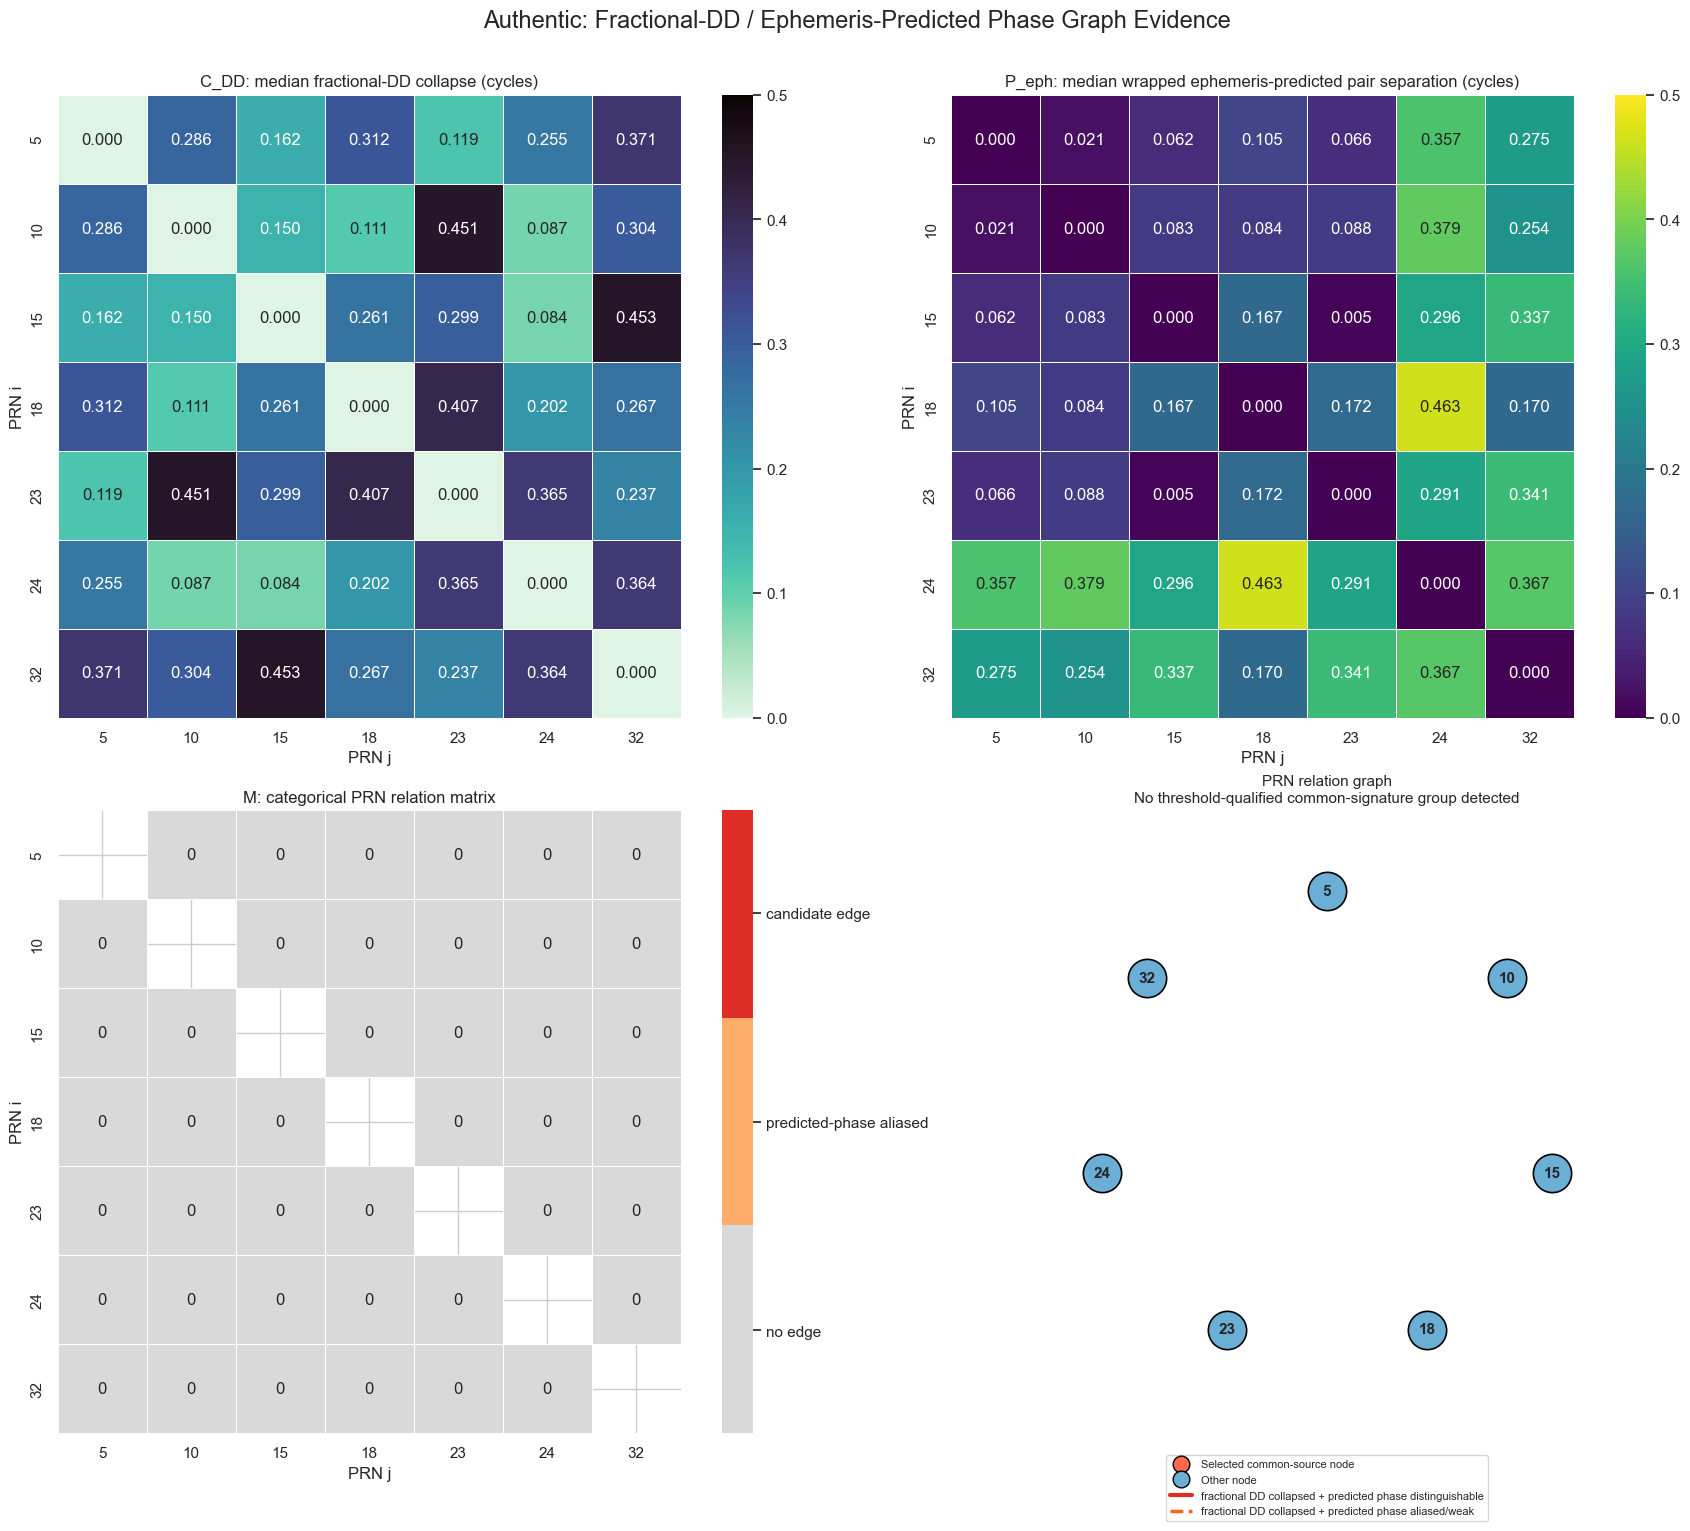

In [7]:
authentic_result = results["Authentic"]
print(authentic_result["scenario_decision"])
print("Selected group:", authentic_result["selected_group"] or "none")
print("Satellite availability and eligibility")
display(authentic_result["availability"])
print("Node relations and graph degree")
display(authentic_result["node_summary"])
print("Connected-component validation")
display(authentic_result["component_summary"].round(5))
print("All authentic pair relations, sorted by fractional-DD collapse")
display(authentic_result["pairs"][[
    "pair", "median_fractional_dd_collapse_cycles",
    "median_ephemeris_predicted_pair_separation_cycles",
    "median_ephemeris_aoa_separation_deg",
    "relation_code", "specific_node_relation", "epoch_count",
]].sort_values("median_fractional_dd_collapse_cycles").round(5))
plot_scenario_evidence(authentic_result)

# 10. Scenario B — Full-spoof recording

For one transmitting antenna, every counterfeit PRN shares the same source projection $\mu_s$:

$$s_{i,k}=\rho\mu_{s,k}+N_i+\beta_k+\epsilon_{i,k}.$$

For any spoof pair,

$$\operatorname{wrap}(s_{i,k}-s_{j,k})\approx0,$$

so all PRNs should be connected by fractional-DD collapse edges. Pairs whose claimed geometry predicts wrapped phase separation of at least $\tau_p$ become red candidate edges; pairs close to an integer-cycle alias appear as orange predicted-phase-aliased collapse edges.

Expected graph:

$$\widehat S=\mathcal V\quad\Longrightarrow\quad\text{full spoof}. $$

All analyzable PRNs form one corroborated common-signature component
Selected group: (11, 12, 13, 15, 18, 20, 23, 24, 29, 30)
Satellite availability and eligibility


,svid,single_difference_epochs,ephemeris_epochs,eligible
0,5,0,120,False
1,11,120,120,True
2,12,120,120,True
3,13,120,120,True
4,15,120,120,True
5,18,120,120,True
6,20,120,120,True
7,23,120,120,True
8,24,120,120,True
9,25,0,120,False


Node relations and graph degree


,svid,fractional_dd_collapse_degree,informative_common_source_degree,predicted_phase_aliased_collapse_degree,selected_common_source_member,graph_evidence_status
0,11,9,8,1,True,corroborated_group_member
1,12,9,7,2,True,corroborated_group_member
2,13,9,8,1,True,corroborated_group_member
3,15,9,7,2,True,corroborated_group_member
4,18,9,9,0,True,corroborated_group_member
5,20,9,8,1,True,corroborated_group_member
6,23,9,9,0,True,corroborated_group_member
7,24,9,9,0,True,corroborated_group_member
8,29,9,7,2,True,corroborated_group_member
9,30,9,8,1,True,corroborated_group_member


Connected-component validation


,component_id,component_svids,component_size,possible_pair_count,observed_pair_count,observed_pair_coverage,collapse_pair_count,collapse_fraction_observed,informative_pair_count,noncollapse_pair_count,corroborated_common_signature_group,rejection_reasons
0,1,"(11, 12, 13, 15, 18, 20, 23, 24, 29, 30)",10,45,45,1.0,45,1.0,40,0,True,()


Every pair relation; orange rows have predicted phase separation below 0.05 cycles


,pair,median_fractional_dd_collapse_cycles,median_ephemeris_predicted_pair_separation_cycles,median_ephemeris_aoa_separation_deg,relation_code,specific_node_relation,epoch_count
17,PRN 13–PRN 15,0.00606,0.39541,23.29149,2.0,fractional DD collapsed + predicted phase dist...,120
24,PRN 15–PRN 18,0.00820,0.25952,47.77249,2.0,fractional DD collapsed + predicted phase dist...,120
22,PRN 13–PRN 29,0.00825,0.37640,22.20248,2.0,fractional DD collapsed + predicted phase dist...,120
18,PRN 13–PRN 18,0.00970,0.34507,24.48100,2.0,fractional DD collapsed + predicted phase dist...,120
1,PRN 11–PRN 13,0.01052,0.24492,44.37142,2.0,fractional DD collapsed + predicted phase dist...,120
2,PRN 11–PRN 15,0.01053,0.35967,21.07992,2.0,fractional DD collapsed + predicted phase dist...,120
33,PRN 18–PRN 29,0.01087,0.27597,46.90216,2.0,fractional DD collapsed + predicted phase dist...,120
27,PRN 15–PRN 24,0.01132,0.10033,64.11428,2.0,fractional DD collapsed + predicted phase dist...,120
26,PRN 15–PRN 23,0.01184,0.21394,12.35342,2.0,fractional DD collapsed + predicted phase dist...,120
7,PRN 11–PRN 29,0.01192,0.36995,21.63507,2.0,fractional DD collapsed + predicted phase dist...,120


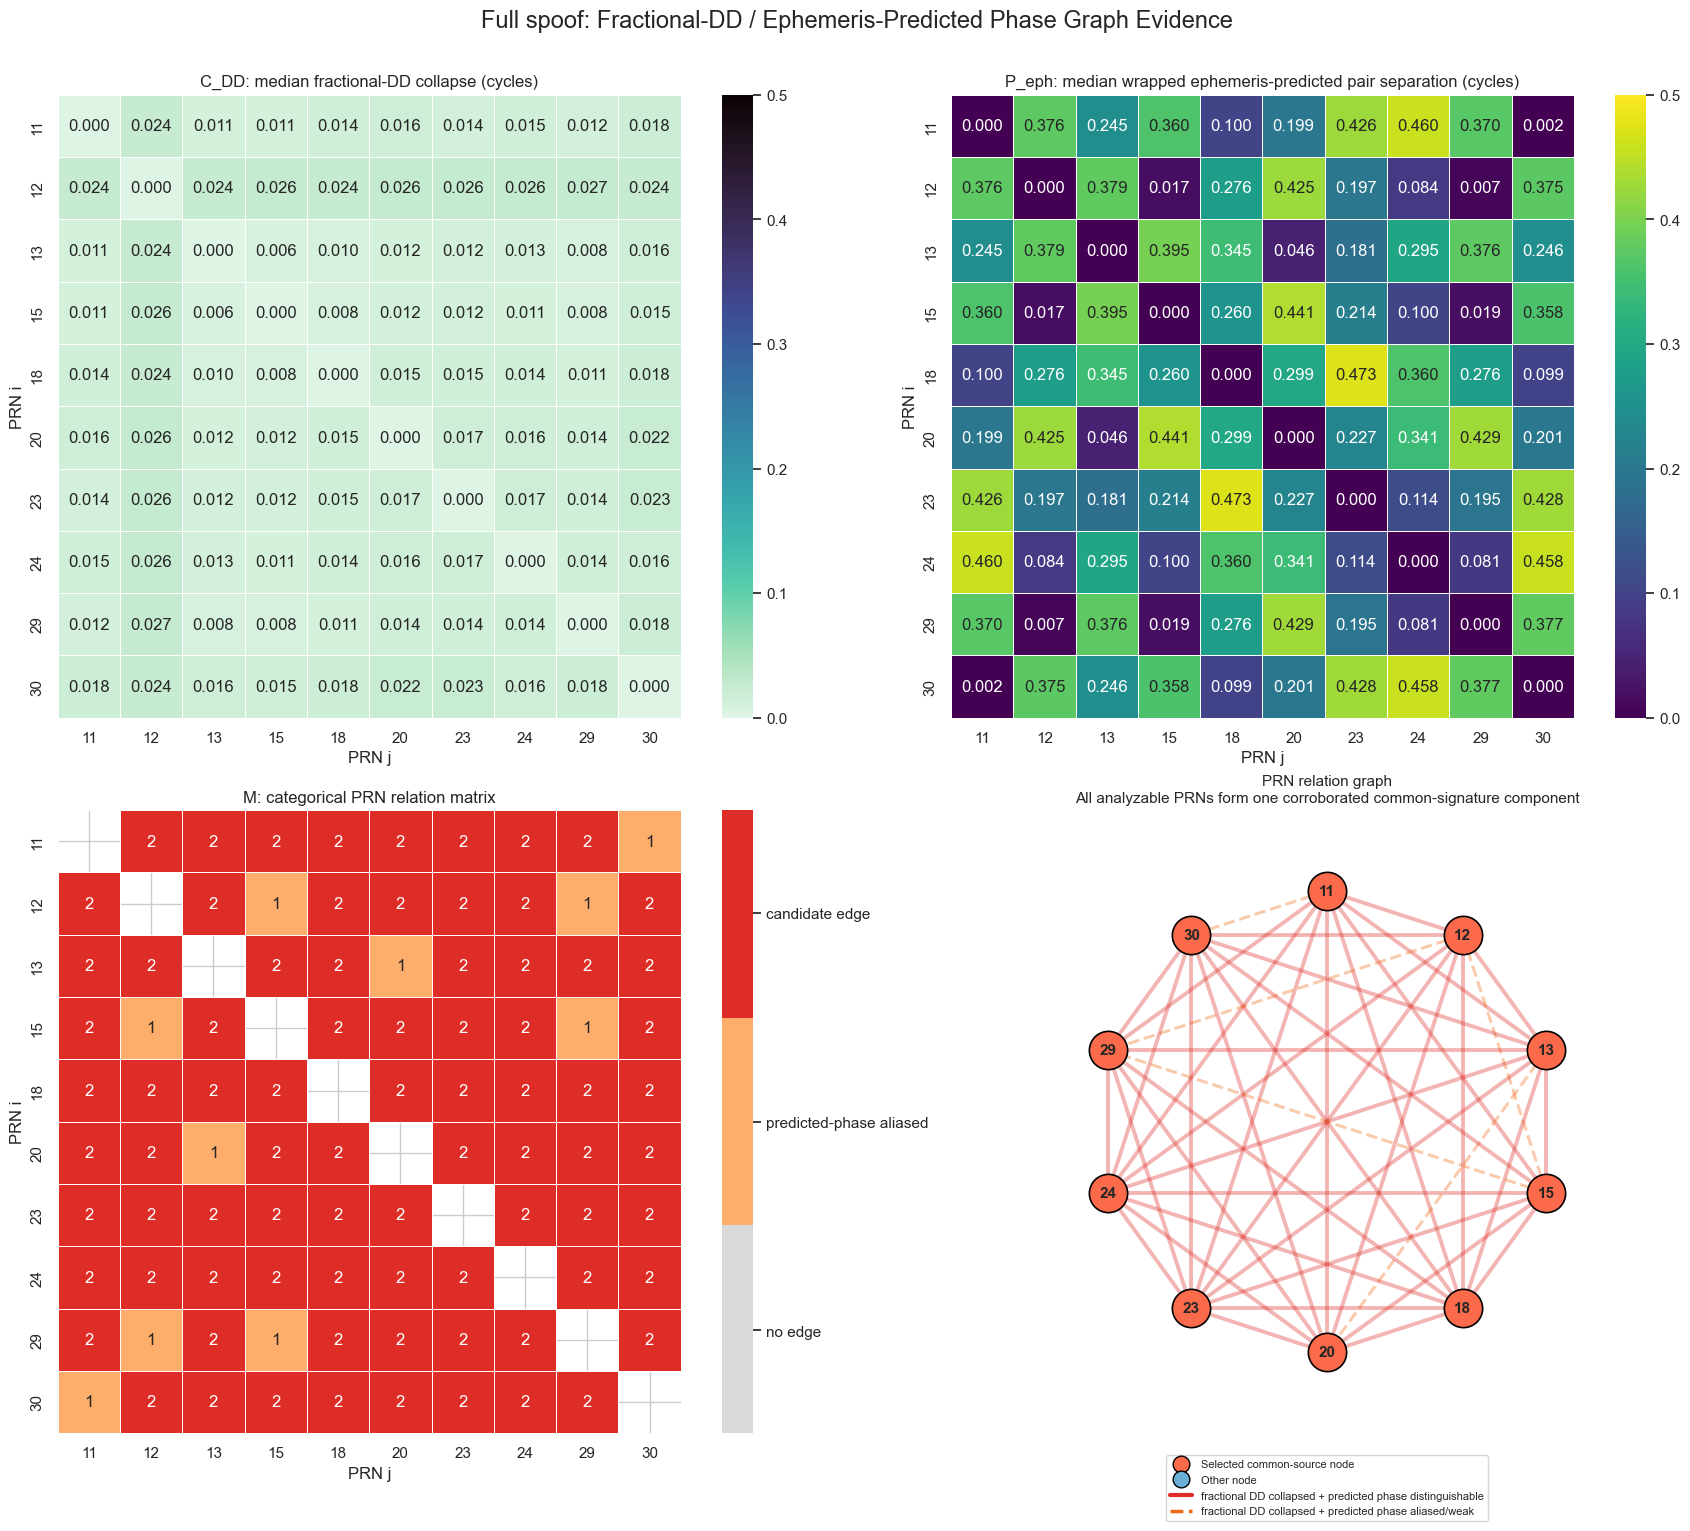

In [8]:
full_result = results["Full spoof"]
print(full_result["scenario_decision"])
print("Selected group:", full_result["selected_group"])
print("Satellite availability and eligibility")
display(full_result["availability"])
print("Node relations and graph degree")
display(full_result["node_summary"])
print("Connected-component validation")
display(full_result["component_summary"].round(5))
print(f"Every pair relation; orange rows have predicted phase separation below {EPHEMERIS_PREDICTED_SEPARATION_THRESHOLD_CYCLES:g} cycles")
display(full_result["pairs"][[
    "pair", "median_fractional_dd_collapse_cycles",
    "median_ephemeris_predicted_pair_separation_cycles",
    "median_ephemeris_aoa_separation_deg",
    "relation_code", "specific_node_relation", "epoch_count",
]].sort_values(["relation_code", "median_fractional_dd_collapse_cycles"], ascending=[False, True]).round(5))
plot_scenario_evidence(full_result)

# 11. Scenario C — Mixed-tracking recording

Let $S\subset\mathcal V$ be counterfeit PRNs from one antenna. Then

$$C_{ij}^{DD}\approx0\quad\text{for }i,j\in S,$$

while pairs involving authentic satellites generally do not collapse. The expected graph contains one red-edge component embedded among isolated blue authentic nodes; that component may contain orange internal pairs, but orange pairs cannot connect or nominate nodes.

Expected decision:

$$\varnothing\ne\widehat S\subsetneq\mathcal V\quad\Longrightarrow\quad\text{mixed tracking}. $$

A pair whose predicted phase is aliased or weakly separated may be orange even when its fractional DD collapses. Such an orange relation is not independently diagnostic, but both endpoints may still belong to a corroborated component through red relations to other members. The executed tables below show which mixed-case pairs have this role at the configured $\tau_p$ operating point.

One strict PRN subset forms a corroborated common-signature component
Selected group: (6, 9, 11, 20)
Satellite availability and eligibility


,svid,single_difference_epochs,ephemeris_epochs,eligible
0,6,34,30,True
1,9,34,30,True
2,10,34,34,True
3,11,34,30,True
4,12,34,34,True
5,13,34,0,False
6,15,34,34,True
7,18,34,34,True
8,20,34,30,True
9,23,34,34,True


Node relations and graph degree


,svid,fractional_dd_collapse_degree,informative_common_source_degree,predicted_phase_aliased_collapse_degree,selected_common_source_member,graph_evidence_status
0,6,3,2,1,True,corroborated_group_member
1,9,3,3,0,True,corroborated_group_member
2,10,0,0,0,False,not_assigned_to_detected_group
3,11,3,3,0,True,corroborated_group_member
4,12,0,0,0,False,not_assigned_to_detected_group
5,15,0,0,0,False,not_assigned_to_detected_group
6,18,0,0,0,False,not_assigned_to_detected_group
7,20,3,2,1,True,corroborated_group_member
8,23,0,0,0,False,not_assigned_to_detected_group
9,24,0,0,0,False,not_assigned_to_detected_group


Connected-component validation


,component_id,component_svids,component_size,possible_pair_count,observed_pair_count,observed_pair_coverage,collapse_pair_count,collapse_fraction_observed,informative_pair_count,noncollapse_pair_count,corroborated_common_signature_group,rejection_reasons
0,1,"(6, 9, 11, 20)",4,6,6,1.0,6,1.0,5,0,True,()


Specific relations inside the discovered common-source component


,pair,median_fractional_dd_collapse_cycles,median_ephemeris_predicted_pair_separation_cycles,median_ephemeris_aoa_separation_deg,relation_code,specific_node_relation,epoch_count
30,PRN 11–PRN 20,0.00302,0.33508,21.37927,2.0,fractional DD collapsed + predicted phase dist...,30
2,PRN 6–PRN 11,0.01033,0.33192,21.19204,2.0,fractional DD collapsed + predicted phase dist...,30
0,PRN 6–PRN 9,0.01072,0.09522,5.58202,2.0,fractional DD collapsed + predicted phase dist...,30
11,PRN 9–PRN 11,0.00439,0.42713,26.77406,2.0,fractional DD collapsed + predicted phase dist...,30
15,PRN 9–PRN 20,0.00390,0.09206,5.39479,2.0,fractional DD collapsed + predicted phase dist...,30
6,PRN 6–PRN 20,0.01082,0.00316,0.18723,1.0,fractional DD collapsed + predicted phase alia...,30


All mixed-case pair relations


,pair,median_fractional_dd_collapse_cycles,median_ephemeris_predicted_pair_separation_cycles,median_ephemeris_aoa_separation_deg,relation_code,specific_node_relation,epoch_count
30,PRN 11–PRN 20,0.00302,0.33508,21.37927,2.0,fractional DD collapsed + predicted phase dist...,30
15,PRN 9–PRN 20,0.00390,0.09206,5.39479,2.0,fractional DD collapsed + predicted phase dist...,30
11,PRN 9–PRN 11,0.00439,0.42713,26.77406,2.0,fractional DD collapsed + predicted phase dist...,30
2,PRN 6–PRN 11,0.01033,0.33192,21.19204,2.0,fractional DD collapsed + predicted phase dist...,30
0,PRN 6–PRN 9,0.01072,0.09522,5.58202,2.0,fractional DD collapsed + predicted phase dist...,30
6,PRN 6–PRN 20,0.01082,0.00316,0.18723,1.0,fractional DD collapsed + predicted phase alia...,30
44,PRN 15–PRN 32,0.03672,0.17971,10.97398,0.0,fractional DD not collapsed → no common-source...,33
37,PRN 12–PRN 23,0.03841,0.25055,44.15019,0.0,fractional DD not collapsed → no common-source...,34
46,PRN 18–PRN 23,0.04061,0.07138,65.20183,0.0,fractional DD not collapsed → no common-source...,34
40,PRN 15–PRN 18,0.05531,0.05619,64.23397,0.0,fractional DD not collapsed → no common-source...,34


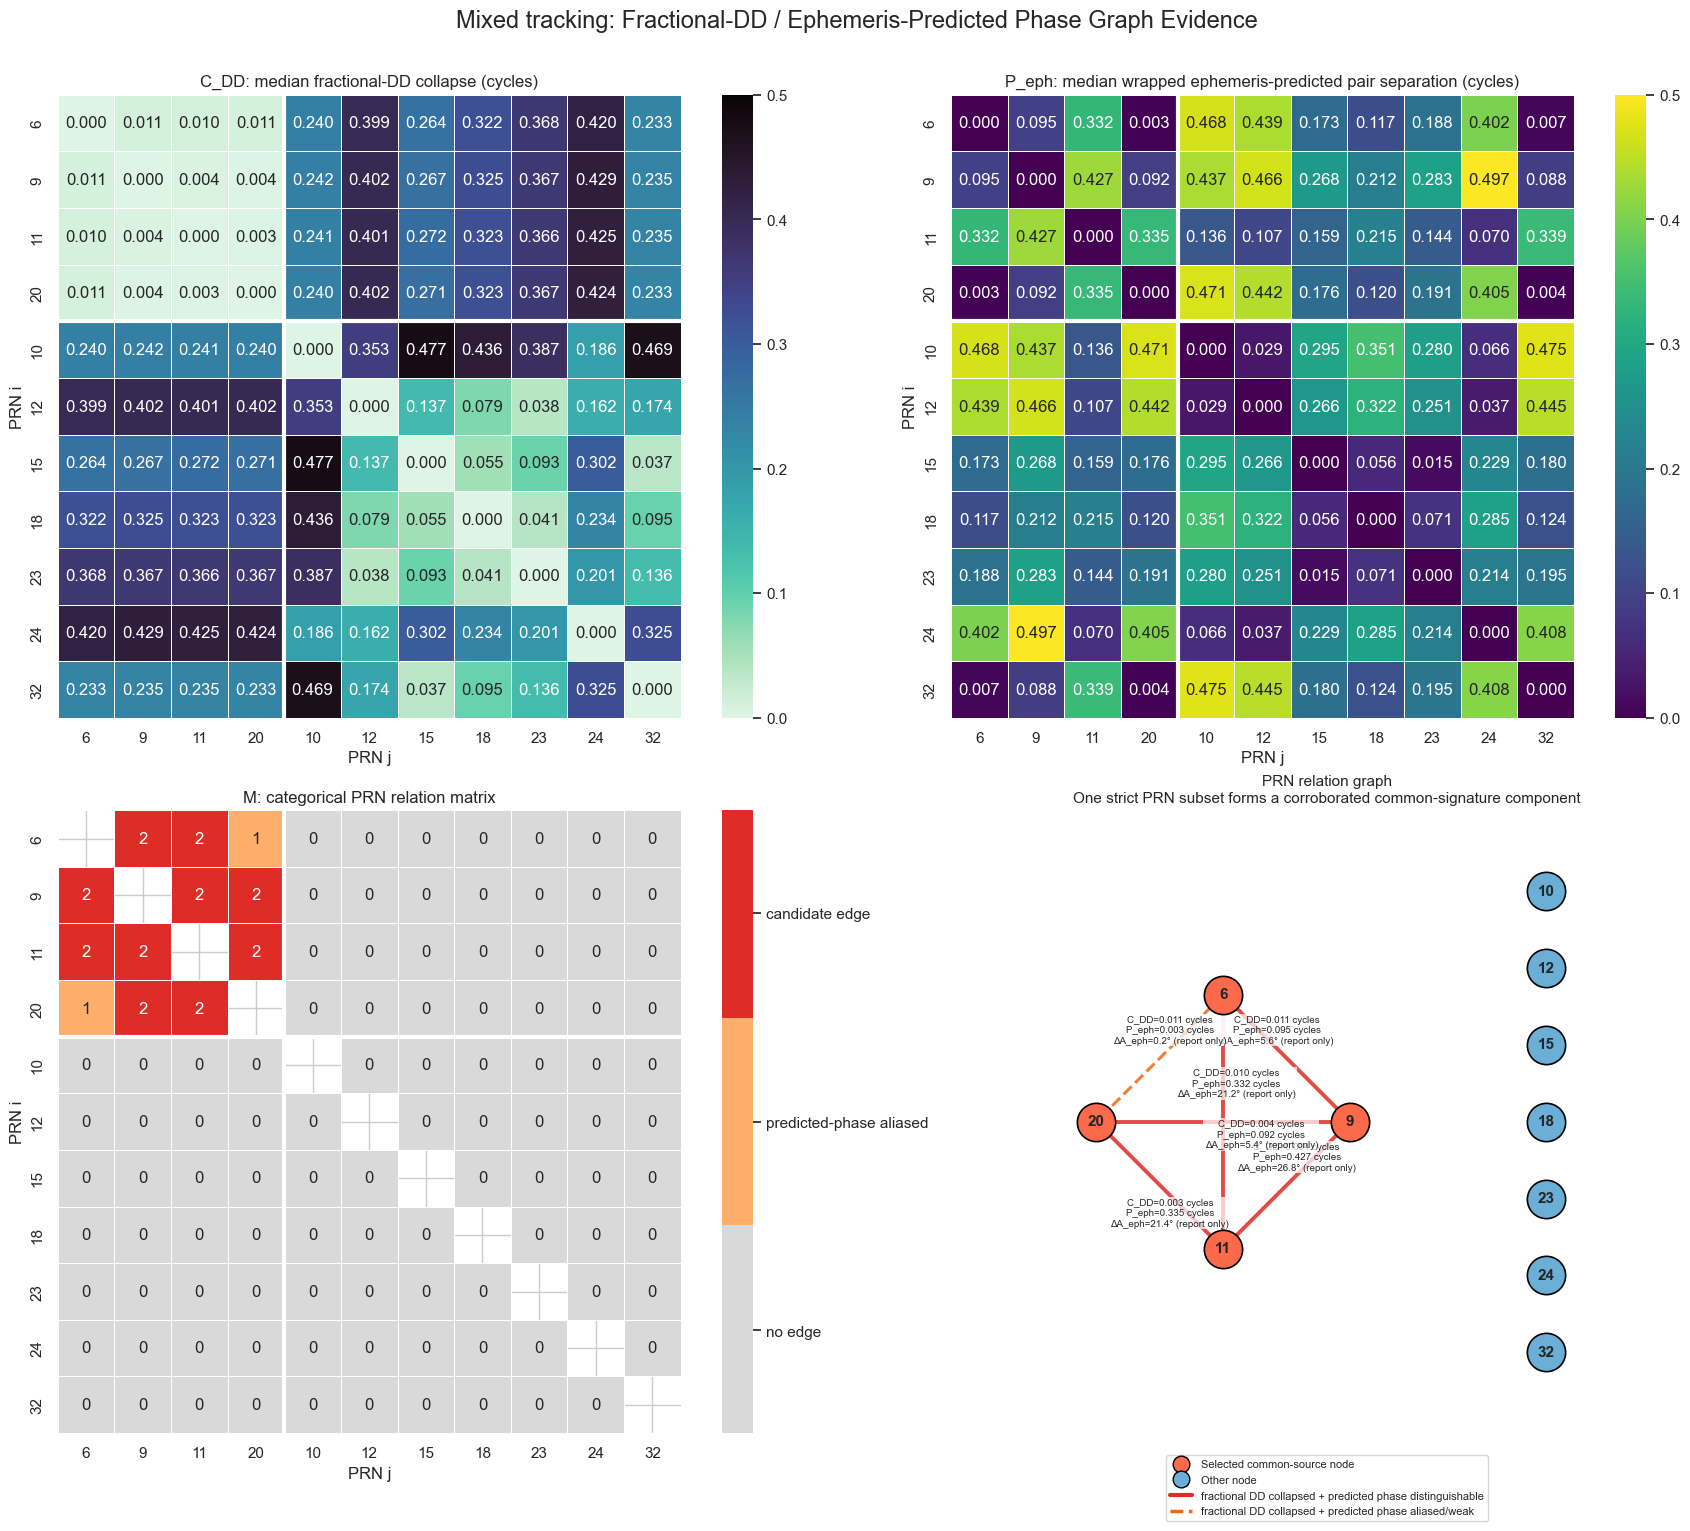

In [9]:
mixed_result = results["Mixed tracking"]
print(mixed_result["scenario_decision"])
print("Selected group:", mixed_result["selected_group"])
print("Satellite availability and eligibility")
display(mixed_result["availability"])
print("Node relations and graph degree")
display(mixed_result["node_summary"])
print("Connected-component validation")
display(mixed_result["component_summary"].round(5))

selected_set = set(mixed_result["selected_group"])
mixed_internal_pairs = mixed_result["pairs"].loc[
    mixed_result["pairs"].left_svid.isin(selected_set)
    & mixed_result["pairs"].right_svid.isin(selected_set)
].copy()
print("Specific relations inside the discovered common-source component")
display(mixed_internal_pairs[[
    "pair", "median_fractional_dd_collapse_cycles",
    "median_ephemeris_predicted_pair_separation_cycles",
    "median_ephemeris_aoa_separation_deg",
    "relation_code", "specific_node_relation", "epoch_count",
]].sort_values(["relation_code", "pair"], ascending=[False, True]).round(5))

print("All mixed-case pair relations")
display(mixed_result["pairs"][[
    "pair", "median_fractional_dd_collapse_cycles",
    "median_ephemeris_predicted_pair_separation_cycles",
    "median_ephemeris_aoa_separation_deg",
    "relation_code", "specific_node_relation", "epoch_count",
]].sort_values(["relation_code", "median_fractional_dd_collapse_cycles"], ascending=[False, True]).round(5))
plot_scenario_evidence(mixed_result)

## 12. Direct visual comparison of graph topology

The scenario decision depends on the selected graph coverage

$$R_S=\frac{|\widehat S|}{|\mathcal V|}.$$

Under the controlled single-spoofer model, the ideal topologies are:

- $R_S=0$: no validated common-source group;
- $R_S=1$: full-spoof common-source graph;
- $0<R_S<1$: mixed-tracking subgraph.

The three network diagrams below use identical node and edge semantics and the fixed $\tau_c$ and $\tau_p$ values defined in Section 2.

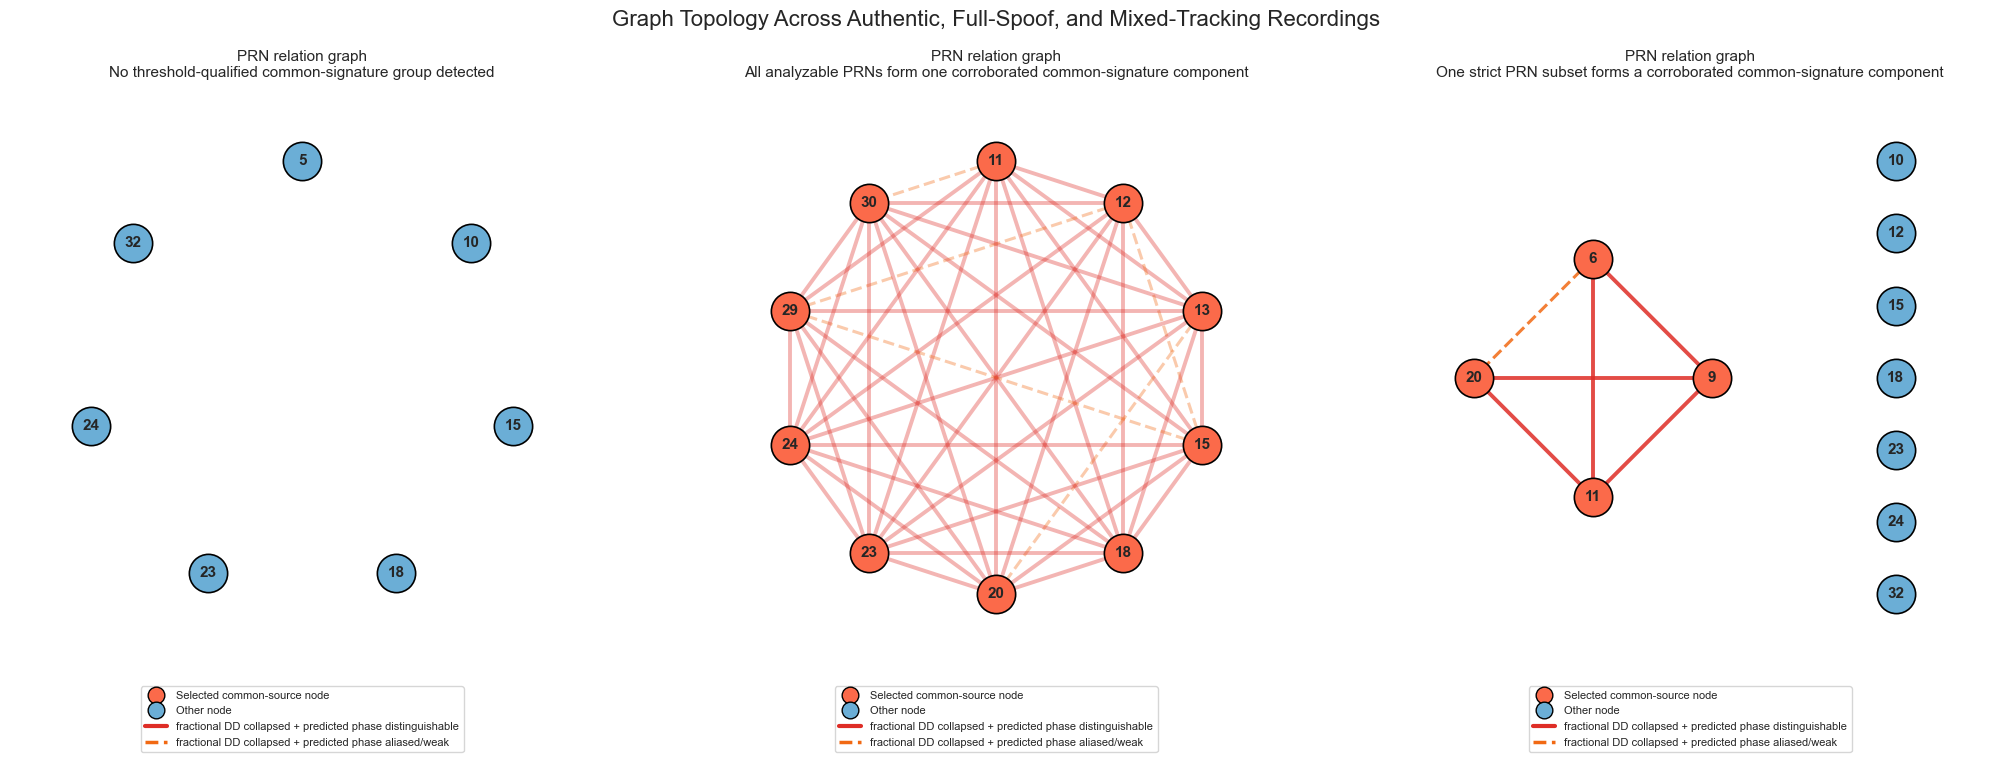

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, result in zip(axes, results.values()):
    draw_relation_graph(result, ax, show_edge_labels=False)
fig.suptitle("Graph Topology Across Authentic, Full-Spoof, and Mixed-Tracking Recordings", fontsize=16, y=1.02)
fig.tight_layout()
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUT_DIR / "three_scenario_graph_comparison.png", dpi=220, bbox_inches="tight")
display(fig)
plt.close(fig)

In [11]:
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    scenario_comparison.to_csv(OUTPUT_DIR / "three_scenario_summary.csv", index=False)
    for name, result in results.items():
        prefix = name.lower().replace(" ", "_")
        result["availability"].to_csv(OUTPUT_DIR / f"{prefix}_availability.csv", index=False)
        result["epoch_pairs"].to_csv(OUTPUT_DIR / f"{prefix}_epoch_pair_evidence.csv", index=False)
        result["pairs"].to_csv(OUTPUT_DIR / f"{prefix}_pair_relations.csv", index=False)
        result["node_summary"].to_csv(OUTPUT_DIR / f"{prefix}_node_summary.csv", index=False)
        result["component_summary"].to_csv(OUTPUT_DIR / f"{prefix}_component_summary.csv", index=False)
    print(f"Saved graph-classifier tables and figures to {OUTPUT_DIR}")
else:
    print("SAVE_OUTPUTS=False; results are displayed inline and no artifacts were written.")

SAVE_OUTPUTS=False; results are displayed inline and no artifacts were written.
